# 04 · Valor de negocio para LATAM
Cuánto vale la alerta y, sobre todo, cuánto de ese valor es del modelo y no de una tabla de tasas por aeropuerto y hora.
Todo sale de `latam_ops.ml.valor_negocio` sobre las predicciones del test 2025 (solo empresas de pasajeros). Los supuestos están en `config/pipeline.yaml` (bloque `valor_negocio`).

In [1]:
import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
os.environ.setdefault("LATAM_MODO", "local")          # "aws" en el clúster (lee s3a://$LAKE_BUCKET)
os.environ.setdefault("LATAM_LAKE_LOCAL", str(RAIZ / "data" / "lake"))
import pandas as pd
import matplotlib.pyplot as plt
from latam_ops.comun.config import cargar_yaml, ruta_repo
VALOR = ruta_repo("docs", "evidencias", "valor")
if not (VALOR / "valor_incremental.csv").exists():
    from latam_ops.ml import valor_negocio
    valor_negocio.ejecutar()
cfg = cargar_yaml("pipeline")["valor_negocio"]
pd.set_option("display.max_colwidth", None)
pd.DataFrame(cfg["escenarios"]).T

,minutos_por_accion,costo_minuto,costo_accion_usd
pesimista,5,brasil_operacional,300
base,10,a4a_sin_combustible,150
optimista,20,a4a_block_completo,50


## Línea base 2025
Salidas de LATAM pasajeros en Brasil (ANAC VRA). La puntualidad de llegada medida en VRA se pone al lado del OTP de Cirium solo como referencia: Cirium mide todo el grupo y en todas las regiones.

In [2]:
pd.read_csv(VALOR / "linea_base.csv").T

,0
anio,2025
empresas,"ARE,LAN,LAP,LNE,LPE,TAM"
vuelos_programados,303471
vuelos_operados,298585
tasa_salida_15,0.1896
tasa_salida_60,0.0254
tasa_llegada_15,0.1783
puntualidad_llegada_vra,0.8217
demora_media_min,6.1
cancelados,4866


## ¿El modelo le gana a una tabla? Mismo número de alertas, cuatro políticas
- **sin sistema**: no se hace nada (beneficio 0);
- **aleatoria**: se revisan vuelos al azar del mismo aeropuerto;
- **referencia**: tasa histórica de demora por aeropuerto y hora (solo train);
- **modelo**: probabilidad del Random Forest.

La referencia recibe en cada aeropuerto el mismo número de alertas que el modelo en el año y las reparte con su propio puntaje.

In [3]:
inc = pd.read_csv(VALOR / "valor_incremental.csv")
sel = inc[(inc.ambito == "red") & (((inc.producto == "ambar") & (inc.regla == "tope10")) | ((inc.producto == "rojo") & (inc.regla == "umbral")))]
sel[["producto", "regla", "politica", "alertas_por_dia", "vp", "precision", "recall", "beneficio_pesimista_usd", "beneficio_base_usd", "beneficio_optimista_usd"]]

,producto,regla,politica,alertas_por_dia,vp,precision,recall,beneficio_pesimista_usd,beneficio_base_usd,beneficio_optimista_usd
40,ambar,tope10,sin_sistema,0.0,0.0,0.0000,0.0000,0.0,0.0,0.0
41,ambar,tope10,aleatoria,145.4,9339.2,0.1760,0.1650,-13151485.0,3543078.0,22821780.0
42,ambar,tope10,referencia,145.4,12536.0,0.2362,0.2214,-12520069.0,6443015.0,30021774.0
43,ambar,tope10,modelo,145.4,14708.0,0.2772,0.2598,-12092291.0,8411924.0,34942274.0
180,rojo,umbral,sin_sistema,0.0,0.0,0.0000,0.0000,0.0,0.0,0.0
181,rojo,umbral,aleatoria,5.5,85.0,0.0421,0.0112,-446725.0,357151.0,1368441.0
182,rojo,umbral,referencia,5.5,120.0,0.0595,0.0158,-410950.0,534647.0,1840582.0
183,rojo,umbral,modelo,5.5,504.0,0.2499,0.0664,-355606.0,836829.0,2845644.0


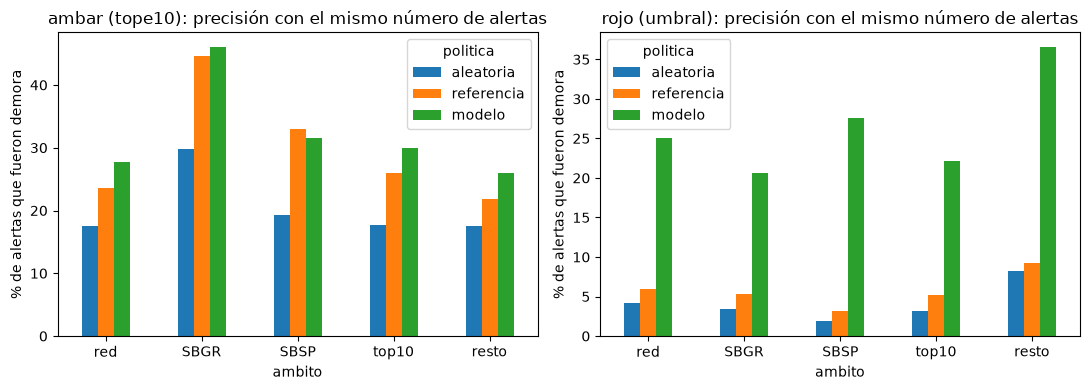

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (prod, regla) in zip(ejes, [("ambar", "tope10"), ("rojo", "umbral")]):
    d = inc[(inc.producto == prod) & (inc.regla == regla) & (inc.politica != "sin_sistema")]
    piv = d.pivot(index="ambito", columns="politica", values="precision").loc[["red", "SBGR", "SBSP", "top10", "resto"], ["aleatoria", "referencia", "modelo"]]
    (piv * 100).plot.bar(ax=ax, rot=0)
    ax.set_title(f"{prod} ({regla}): precisión con el mismo número de alertas"); ax.set_ylabel("% de alertas que fueron demora")
plt.tight_layout(); plt.show()

La alerta roja acierta unas cuatro veces más que la tabla (24 % frente a 6 %). La ámbar le gana a la tabla en la red y en los aeropuertos fuera del top 10, pero **en SBGR y SBSP queda empatada**: ahí el riesgo depende sobre todo del avión que llega, y VRA no trae la matrícula.

## Intervalos de confianza (bootstrap de 1 000 remuestras de días)
Se remuestrean días completos porque los vuelos de un mismo día comparten clima y estado de la red.

In [5]:
ic = pd.read_csv(VALOR / "intervalos_bootstrap.csv")
claves = ["precision_modelo", "precision_referencia", "recall_modelo", "beneficio_modelo", "incremento_modelo_vs_referencia"]
ic[(ic.regla.isin(["tope10", "umbral"])) & (ic.ambito.isin(["red", "SBGR", "SBSP"])) & ic.estadistico.isin(claves)
   & (((ic.producto == "ambar") & (ic.regla == "tope10")) | ((ic.producto == "rojo") & (ic.regla == "umbral")))]

,producto,regla,ambito,estadistico,puntual,p2_5,mediana,p97_5
113,ambar,tope10,red,precision_referencia,2.362000e-01,2.249000e-01,2.363000e-01,2.471000e-01
116,ambar,tope10,red,precision_modelo,2.772000e-01,2.634000e-01,2.771000e-01,2.900000e-01
117,ambar,tope10,red,recall_modelo,2.598000e-01,2.519000e-01,2.596000e-01,2.671000e-01
118,ambar,tope10,red,beneficio_modelo,8.411924e+06,7.749596e+06,8.395704e+06,9.017372e+06
119,ambar,tope10,red,incremento_modelo_vs_referencia,1.968909e+06,1.642856e+06,1.962929e+06,2.270785e+06
124,ambar,tope10,SBGR,precision_referencia,4.463000e-01,4.241000e-01,4.455000e-01,4.680000e-01
127,ambar,tope10,SBGR,precision_modelo,4.608000e-01,4.375000e-01,4.605000e-01,4.849000e-01
128,ambar,tope10,SBGR,recall_modelo,7.760000e-02,7.440000e-02,7.750000e-02,8.100000e-02
129,ambar,tope10,SBGR,beneficio_modelo,1.216962e+06,1.164526e+06,1.216582e+06,1.266145e+06
130,ambar,tope10,SBGR,incremento_modelo_vs_referencia,-3.867920e+03,-4.587629e+04,-4.075130e+03,4.227602e+04


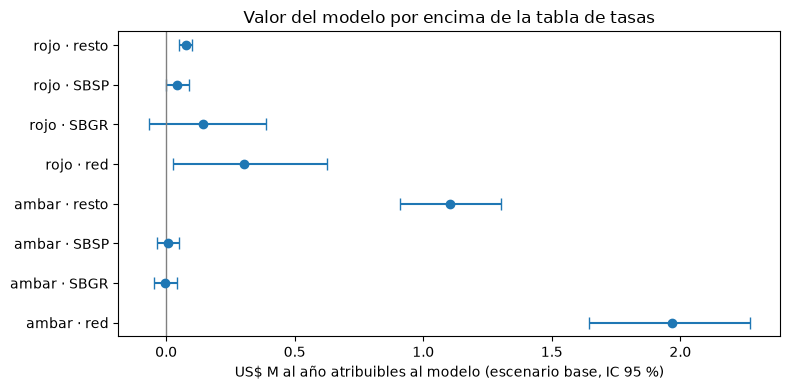

In [6]:
d = ic[(ic.estadistico == "incremento_modelo_vs_referencia") & (ic.ambito.isin(["red", "SBGR", "SBSP", "resto"]))
       & (((ic.producto == "ambar") & (ic.regla == "tope10")) | ((ic.producto == "rojo") & (ic.regla == "umbral")))].copy()
d["etiqueta"] = d.producto + " · " + d.ambito
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(d.puntual / 1e6, d.etiqueta, xerr=[(d.puntual - d.p2_5) / 1e6, (d.p97_5 - d.puntual) / 1e6], fmt="o", capsize=4)
ax.axvline(0, color="grey", lw=1); ax.set_xlabel("US$ M al año atribuibles al modelo (escenario base, IC 95 %)")
ax.set_title("Valor del modelo por encima de la tabla de tasas"); plt.tight_layout(); plt.show()

## Capacidad del CCO: cuántos vuelos por aeropuerto y día
`tope K`: alertas sobre el umbral con un máximo de K por aeropuerto y día. `cuota K`: siempre los K de mayor riesgo, haya o no riesgo. La cuota desperdicia acciones en días tranquilos: el modelo sabe sobre todo **qué días** vienen malos.

In [7]:
cap = pd.read_csv(VALOR / "capacidad_topk.csv")
cap[(cap.ambito == "red") & (cap.escenario == "base")][["producto", "regla", "k_por_aeropuerto_dia", "alertas_por_dia", "precision", "precision_referencia", "recall", "beneficio_neto_usd", "incremento_vs_referencia_usd", "tasa15_antes", "tasa15_despues"]]

,producto,regla,k_por_aeropuerto_dia,alertas_por_dia,precision,precision_referencia,recall,beneficio_neto_usd,incremento_vs_referencia_usd,tasa15_antes,tasa15_despues
1,ambar,tope5,5,114.1,0.2736,0.2320,0.2013,6453865,1602631,0.1896,0.1752
16,ambar,tope10,10,145.4,0.2772,0.2362,0.2598,8411924,1968909,0.1896,0.1710
31,ambar,tope20,20,172.6,0.2870,0.2427,0.3193,10598523,2512974,0.1896,0.1666
46,ambar,tope40,40,206.1,0.3017,0.2580,0.4008,13764914,2836360,0.1896,0.1604
61,ambar,cuota5,5,229.3,0.1970,0.1888,0.2912,6779941,716256,0.1896,0.1681
76,ambar,cuota10,10,334.7,0.1865,0.1835,0.4025,8749457,474580,0.1896,0.1593
91,ambar,cuota20,20,455.8,0.1765,0.1753,0.5186,10275011,192222,0.1896,0.1500
106,ambar,cuota40,40,550.6,0.1788,0.1790,0.6347,12849046,-139798,0.1896,0.1409
121,rojo,tope5,5,2.5,0.2589,0.0714,0.0306,338522,137449,0.1896,0.1893
136,rojo,tope10,10,3.1,0.2463,0.0629,0.0372,444562,173573,0.1896,0.1891


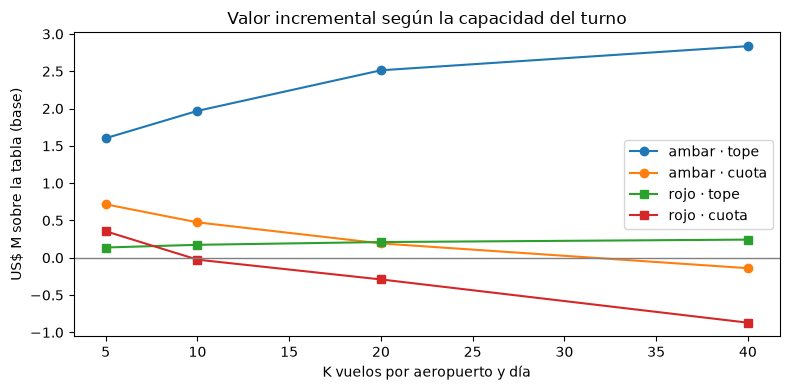

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for prod, est in [("ambar", "-o"), ("rojo", "-s")]:
    for tipo in ("tope", "cuota"):
        d = cap[(cap.ambito == "red") & (cap.escenario == "base") & (cap.producto == prod) & cap.regla.str.startswith(tipo)].sort_values("k_por_aeropuerto_dia")
        ax.plot(d.k_por_aeropuerto_dia, d.incremento_vs_referencia_usd / 1e6, est, label=f"{prod} · {tipo}")
ax.axhline(0, color="grey", lw=1); ax.set_xlabel("K vuelos por aeropuerto y día"); ax.set_ylabel("US$ M sobre la tabla (base)")
ax.set_title("Valor incremental según la capacidad del turno"); ax.legend(); plt.tight_layout(); plt.show()

## Punto de equilibrio
En vez de defender una fracción mitigable inventada: ¿cuántos minutos tiene que ahorrar cada acción para que la lista se pague? `fraccion_equilibrio` es la misma cuenta expresada como parte de los minutos de demora alertados (recortados a 2 h). Se marca como *no plausible* lo que exige más del 46 % (la demora heredada del vuelo anterior es el 46 % de los minutos en Europa, CODA 2024).

In [9]:
eq = pd.read_csv(VALOR / "punto_equilibrio.csv")
t = eq[(eq.ambito == "red") & (eq.politica == "modelo") & (((eq.producto == "ambar") & (eq.regla == "tope10")) | ((eq.producto == "rojo") & (eq.regla == "umbral")))]
t.pivot_table(index=["producto", "costo_minuto"], columns="costo_accion_usd", values="minutos_por_accion_equilibrio")

costo_accion_usd              50     150    300    1500
producto costo_minuto                                  
ambar    a4a_block_completo   0.96   2.97   6.40    NaN
         a4a_sin_combustible  1.36   4.32   9.69    NaN
         brasil_operacional   3.40  12.36  45.07    NaN
rojo     a4a_block_completo   0.58   1.74   3.54  20.74
         a4a_sin_combustible  0.82   2.49   5.08  33.82
         brasil_operacional   1.97   6.17  13.14    NaN

## Escenarios (red completa)
Una acción ahorra como máximo m minutos (5, 10 o 20) y nunca más que la demora del vuelo; el costo por minuto es en tierra (sin combustible en el escenario base).

In [10]:
esc = pd.read_csv(VALOR / "valor_escenarios.csv")
esc[((esc.producto == "ambar") & (esc.regla == "tope10")) | ((esc.producto == "rojo") & (esc.regla == "umbral"))][
    ["producto", "regla", "escenario", "minutos_por_accion", "costo_minuto_usd", "costo_accion_usd", "alertas", "minutos_ahorrados", "beneficio_neto_usd", "incremento_vs_referencia_usd", "tasa15_antes", "tasa15_despues", "pasajeros_bajo_2h", "minutos_pasajero_ahorrados"]]

,producto,regla,escenario,minutos_por_accion,costo_minuto_usd,costo_accion_usd,alertas,minutos_ahorrados,beneficio_neto_usd,incremento_vs_referencia_usd,tasa15_antes,tasa15_despues,pasajeros_bajo_2h,minutos_pasajero_ahorrados
6,ambar,tope10,pesimista,5,28.90,300.0,53064,132419,-12092291,427778,0.1896,0.1790,10875,23151034
7,ambar,tope10,base,10,69.07,150.0,53064,237028,8411924,1968909,0.1896,0.1710,19384,41410054
8,ambar,tope10,optimista,20,98.41,50.0,53064,382029,34942274,4920500,0.1896,0.1599,31889,66643926
27,rojo,umbral,pesimista,5,28.90,300.0,2017,8633,-355606,55344,0.1896,0.1892,2022,1366601
28,rojo,umbral,base,10,69.07,150.0,2017,16496,836829,302181,0.1896,0.1887,3202,2607018
29,rojo,umbral,optimista,20,98.41,50.0,2017,29941,2845644,1005061,0.1896,0.1879,5220,4711721


## Sensibilidad del umbral (C_FN/C_FP)

In [11]:
pd.read_csv(VALOR / "sensibilidad_umbral.csv")

,objetivo,razon_cfn_cfp,umbral,vp,fp,fn,vn,precision,recall,alertas_por_dia,tasa_alerta
0,y_demora15,3.0,0.24,23504,36435,33112,205534,0.3921,0.4151,163.8,0.2007
1,y_demora15,5.0,0.18,36864,82630,19752,159339,0.3085,0.6511,326.5,0.4002
2,y_demora15,10.0,0.10,52580,181333,4036,60636,0.2248,0.9287,639.1,0.7834
3,y_demora60,3.0,0.17,353,618,7233,290381,0.3635,0.0465,2.7,0.0033
4,y_demora60,5.0,0.13,504,1513,7082,289486,0.2499,0.0664,5.5,0.0068
5,y_demora60,10.0,0.08,1002,5965,6584,285034,0.1438,0.1321,19.0,0.0233


## Hallazgos accionables

In [12]:
for nombre in ("aeropuertos", "franjas", "clima", "red"):
    print(f"\n== {nombre}")
    display(pd.read_csv(VALOR / f"hallazgos_{nombre}.csv"))


== aeropuertos


,grupo,vuelos,tasa_demora15
0,SBGR,72769,0.2977
1,SBCF,6673,0.2016
2,SBSP,39859,0.1922
3,SBCT,7506,0.1721
4,SBGO,4524,0.1616
5,SCEL,6505,0.1594
6,SBSV,7070,0.1549
7,SBFL,6105,0.1541
8,SBGL,11883,0.1495
9,SBPA,9264,0.1455



== franjas


,grupo,vuelos,tasa_demora15
0,18-23,75006,0.2627
1,12-17,96514,0.2149
2,06-11,96732,0.1381
3,00-05,30333,0.0927



== clima


,grupo,vuelos,tasa_demora15
0,tormenta,6473,0.2999
1,niebla,1824,0.2971
2,lluvia,7896,0.2775
3,IFR/LIFR sin niebla,21899,0.2145
4,VFR/MVFR sin fenómenos,254298,0.1820
5,sin METAR,6195,0.1558



== red


,grupo,vuelos,tasa_demora15
0,>=50 %,19737,0.3368
1,30-50 %,28100,0.3344
2,10-30 %,83501,0.2256
3,<10 %,119738,0.1320
4,sin salidas previas,47509,0.1247


## Trazabilidad del valor (sección 6.1)
Las filas 1 y 2 tienen mecanismo y costo; las de programación, clima y red están rotuladas como cotas superiores.

In [13]:
pd.read_csv(VALOR / "trazabilidad.csv")

,objetivo,hallazgo,decision,responsable,efecto
0,Avisar a T-2 h los vuelos con riesgo de salir con 15 min o más (ámbar),"Con las alertas sobre el umbral, con un máximo de 10 por aeropuerto y día (145.4 por día) el modelo acierta 27.7 % frente a 23.6 % de una tabla de tasas por aeropuerto y hora con las mismas alertas (test 2025-01..2025-12, solo pasajeros)","Entregar la lista al jefe de turno a T-2 h para decidir la acción (reserva de avión o tripulación, prioridad de rampa, re-protección de conexiones, aviso a pasajeros)",Jefe de turno del CCO de LATAM Brasil,"Atribuible al modelo y no a la tabla: US$ 1.97 M al año (IC 95 % US$ 1.64 M a US$ 2.27 M) en el escenario base. La lista se paga si cada acción ahorra al menos 4.32 min (US$ 69/min) o 12.36 min (US$ 28,9/min). Salidas con 15 min o más: 18.96 % -> 17.10 % si cada acción ahorra 10 min"
1,Avisar a T-2 h los vuelos con riesgo de salir con 60 min o más (rojo),"Con todas las alertas sobre el umbral (5.5 por día) el modelo acierta 25.0 % frente a 5.9 % de una tabla de tasas por aeropuerto y hora con las mismas alertas (test 2025-01..2025-12, solo pasajeros)","Entregar la lista al jefe de turno a T-2 h para decidir la acción (reserva de avión o tripulación, prioridad de rampa, re-protección de conexiones, aviso a pasajeros)",Jefe de turno del CCO de LATAM Brasil,"Atribuible al modelo y no a la tabla: US$ 302,181 al año (IC 95 % US$ 27,114 a US$ 627,164) en el escenario base. La lista se paga si cada acción ahorra al menos 2.49 min (US$ 69/min) o 6.17 min (US$ 28,9/min). Salidas con 15 min o más: 18.96 % -> 18.87 % si cada acción ahorra 10 min"
2,Usar la alerta ámbar en el hub SBGR,"En SBGR la lista acierta 46.1 % y la tabla de tasas 44.6 % con las mismas alertas; diferencia de valor US$ -3,868 (IC 95 % US$ -45,876 a US$ 42,276)",En este hub el modelo no le gana a la tabla: usar la tabla por hora (más simple) y mejorar el modelo con la rotación de aviones antes de adoptarlo,Coordinador de hub del CCO en SBGR,Beneficio neto de actuar sobre la lista en el escenario base: US$ 1.22 M al año
3,Usar la alerta ámbar en el hub SBSP,"En SBSP la lista acierta 31.6 % y la tabla de tasas 33.0 % con las mismas alertas; diferencia de valor US$ 6,976 (IC 95 % US$ -36,029 a US$ 50,301)",En este hub el modelo no le gana a la tabla: usar la tabla por hora (más simple) y mejorar el modelo con la rotación de aviones antes de adoptarlo,Coordinador de hub del CCO en SBSP,"Beneficio neto de actuar sobre la lista en el escenario base: US$ 529,111 al año"
4,Ajustar la programación donde la demora se acumula,La franja 18-23 h tiene 26.3 % de salidas con 15 min o más (red: 19.0 %),"Estudiar más holgura de giro en las rotaciones de la franja 18-23 h, con su costo en utilización",Planeamiento de red y programación,"Cota superior, no estimación: 5481 salidas menos con 15 min o más si la franja llegara al promedio; el efecto real depende de cuánta holgura se agregue y no se modeló"
5,Anticipar el efecto del clima reportado en el METAR,Con tormenta en el origen a T-2 h la tasa es 30.0 % frente a 18.2 % con tiempo VFR (6473 vuelos en el periodo),"Protocolo de clima: si el METAR de T-2 h reporta tormenta, esos vuelos entran a la lista de revisión",Despacho de vuelos y meteorología del CCO,"Cota superior: 6473 salidas con riesgo 1.6 veces mayor; ya están dentro del puntaje del modelo, no es un ahorro adicional"
6,Cortar la propagación de demoras en la red,"Cuando >=50 % de las salidas previas del origen ya iban atrasadas, la tasa sube a 33.7 %","Si en [T-4 h, T-2 h) más del 30 % de las salidas del aeropuerto van atrasadas, escalar al coordinador del hub",Coordinador de hub del CCO,"Cota superior: 19737 salidas del periodo en esa condición; el CCO ya observa este estado en tiempo real, el aporte es avisarlo de forma sistemática"
7,Mantener la calidad de la alerta en el tiempo,Las métricas cambian por temporada y la red cambia (deriva medida con PSI),Revisar cada mes el KPI K4 (precisión y recall de la alerta) y re

## Supuestos y fuentes

In [14]:
for k, v in cfg["costos_minuto"].items():
    print(f"{k}: US$ {v['usd']}/min\n  {v['fuente']}\n")
print(cfg["referencias_costo"]); print(); print(cfg["resolucion_anac_400"]); print(); print(cfg["nota_supuestos"])

brasil_operacional: US$ 28.9/min
  Bendinelli, Bettini y Oliveira (2015), "Os custos diretos de voos que chegam atrasados em aeroportos brasileiros", XIV SITRAER, ITA, Tabla 2: en 2010 el costo operacional de los atrasos en Brasil fue US$ 165,4 M para 7,71 M minutos = US$ 21,46 por minuto (dólares de 2013). Actualizado a dólares de 2024 con el IPC de EE. UU. (BLS CPI-U promedio anual 313,689 / 232,957 = 1,3466). https://repositorio.usp.br/bitstreams/30d65449-452b-492d-9523-fe90cabb9b80 (consultado el 12-nov-2026)

a4a_sin_combustible: US$ 69.07/min
  Airlines for America, U.S. Passenger Carrier Delay Costs (2025): US$ 98,41 por minuto de block time, de los que 29,34 son combustible. Con el avión en la puerta los motores están apagados, así que se descuenta el combustible: tripulación 37,01 + mantenimiento 18,35 + propiedad 9,76 + otros 3,95. https://www.airlines.org/dataset/u-s-passenger-carrier-delay-costs/ (consultado el 11-nov-2026)

a4a_block_completo: US$ 98.41/min
  Airlines for 